In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [36]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

In [59]:
df=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2275955_ejection_results.txt', header=None)
df2=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2299743_ejection_results.txt', header=None)

In [60]:
df.columns=['mass','time','result','particle_id']
df2.columns=['mass','time','result','particle_id']

In [61]:
df.mass.unique()

array([1.00000000e-02, 5.01187234e-03, 2.51188643e-03, 1.25892541e-03,
       1.58489319e-04, 7.94328235e-05, 6.30957344e-04, 3.16227766e-04])

In [62]:
df.tail()

,mass,time,result,particle_id
1992,0.000079,2.460902e+06,Ejected,718
1993,0.000079,2.522900e+06,Ejected,31
1994,0.000079,2.523900e+06,Ejected,136
1995,0.000079,2.541899e+06,Ejected,563
1996,0.000079,2.571898e+06,Ejected,363


In [63]:
ejection_df,c=compute_cumulative_outcome_fractions(df, df.mass.unique(), [800,800,800,800,800,800,800,800])
ejection_df_2,c2=compute_cumulative_outcome_fractions(df2, df2.mass.unique(), [800,800,800,800,800,800,800,800])

In [64]:
ejection_df=ejection_df.sort_index(ascending=False)
ejection_df_2=ejection_df_2.sort_index(ascending=False)

In [56]:
ejection_df

,0.000000e+00,4.987517e+03,4.999801e+03,6.982524e+03,1.298370e+04,1.399889e+04,1.592060e+04,1.791067e+04,1.890571e+04,1.990074e+04,...,3.686708e+06,3.806698e+06,3.877693e+06,4.033680e+06,4.461646e+06,4.509643e+06,4.606635e+06,5.048600e+06,5.077598e+06,5.168590e+06
0.010000,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00250,0.00625,0.01125,0.01875,...,0.55625,0.55625,0.55625,0.55625,0.55625,0.55625,0.55625,0.55625,0.55625,0.55625
0.005012,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.45375,0.45375,0.45375,0.45375,0.45375,0.45375,0.45375,0.45375,0.45375,0.45375
0.002512,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.37875,0.37875,0.37875,0.37875,0.37875,0.37875,0.37875,0.37875,0.37875,0.37875
0.001259,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.32125,0.32125,0.32125,0.32125,0.32125,0.32125,0.32125,0.32125,0.32125,0.32125
0.000631,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.26500,0.26500,0.26500,0.26500,0.26500,0.26500,0.26500,0.26500,0.26500,0.26500
0.000316,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.23000,0.23000,0.23000,0.23000,0.23000,0.23000,0.23000,0.23000,0.23000,0.23000
0.000158,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.20375,0.20500,0.20625,0.20750,0.20875,0.21000,0.21125,0.21250,0.21375,0.21500
0.000079,0.0,0.0,0.00125,0.00125,0.00125,0.00125,0.00125,0.00125,0.00125,0.00125,...,0.02875,0.02875,0.02875,0.02875,0.02875,0.02875,0.02875,0.02875,0.02875,0.02875


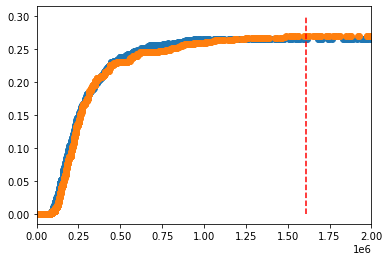

In [ ]:
plt.scatter(ejection_df.columns,ejection_df.loc[ejection_df.index.unique()[4]])
plt.scatter(ejection_df_2.columns,ejection_df_2.loc[ejection_df_2.index.unique()[4]])
plt.xlim(0,2e6)
plt.vlines(x=1611491.688909667, ymin=0, ymax=0.3, color='r', linestyle='--', label='tmax')

In [92]:
df=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Particle_Tracking/2299743-5_initial_particles.txt', header=None)

In [93]:
df.columns=['a','e','id']

(array([12., 24., 42., 50., 45., 40., 56., 56., 70., 54., 58., 51., 45.,
        45., 32., 31., 17., 17., 10., 15.,  5.,  8.,  5.,  4.,  4.,  1.,
         1.,  0.,  0.,  2.]),
 array([0.00536727, 0.01803329, 0.03069931, 0.04336534, 0.05603136,
        0.06869739, 0.08136341, 0.09402943, 0.10669546, 0.11936148,
        0.1320275 , 0.14469353, 0.15735955, 0.17002557, 0.1826916 ,
        0.19535762, 0.20802364, 0.22068967, 0.23335569, 0.24602171,
        0.25868774, 0.27135376, 0.28401978, 0.29668581, 0.30935183,
        0.32201785, 0.33468388, 0.3473499 , 0.36001592, 0.37268195,
        0.38534797]),
 <BarContainer object of 30 artists>)

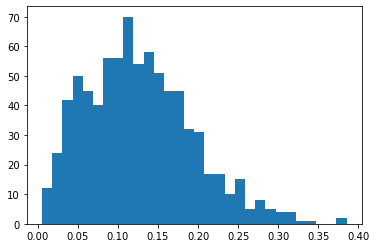

In [94]:
plt.hist(df.e, bins=30)

In [45]:


def find_t_stop(ejection_df, index):
    f = ejection_df.iloc[index].to_numpy()
    t = ejection_df.columns.to_numpy(dtype=float)

    peak_slope = -np.inf
    t_peak = None
    consecutive = 0

    for i in range(5, len(t)):
        # Update peak slope using a 5-point window
        slope = (f[i] - f[i-5]) / (t[i] - t[i-5])

        if slope > peak_slope:
            peak_slope = slope
            t_peak = t[i]

        # Look back 3*t_peak
        t_back = t[i] - 3*t_peak

        if f[i] < 0.07 or t_back < t[0]:
            continue

        j = np.searchsorted(t, t_back, side='right') - 1

        if f[i] - f[j] < 0.04:
            consecutive += 1
        else:
            consecutive = 0

        if consecutive >= 3:
            return t[i]

    return None



In [46]:
t_stop = find_t_stop(ejection_df, index=1)
print(t_stop)

3877692.7257342665
